# 05 · Model 3 — Gaussian process with a Tanimoto kernel

Models 1 and 2 are linear in fixed features. This one works from similarity instead: molecules
sharing substructures should behave alike, with

    k(x, x') = amplitude * |x AND x'| / |x OR x'| + bias

the graph kernel of Ralaivola et al. (2005). Inference is the Laplace approximation for GP
classification (Rasmussen & Williams Alg. 3.1); the amplitude and bias come from the
approximate marginal likelihood.

Fitted by `scripts/fit_model3.py`; this notebook reads the saved predictions.

The proposal's reason for wanting a GP is not accuracy. It is this claim:

> Its uncertainty grows for molecules unlike the training set, which gives a natural
> applicability domain.

That claim has two links — **variance tracks novelty**, and **novelty tracks error** — and this
notebook tests them separately, because only one of them holds.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
ADDITIVE = "formate"

cur = pd.read_csv(PROC / "wif_curated.csv")
fp = np.load(PROC / "morgan_2048_r2.npz", allow_pickle=True)["fp"].astype(np.float32)
y = cur[f"flies_{ADDITIVE}"].to_numpy()

def tanimoto(A, B):
    inter = A @ B.T
    a, b = A.sum(1), B.sum(1)
    return inter / np.maximum(a[:, None] + b[None, :] - inter, 1e-9)

def load3(split):
    d = np.load(PROC / f"model3_{ADDITIVE}_{split}.npz")
    return {k: d[k] for k in d.files}

summary = pd.read_csv(PROC / "model3_summary.csv")
summary[["split", "amplitude", "bias", "log marginal", "AUC", "log loss", "Brier"]].round(3)

,split,amplitude,bias,log marginal,AUC,log loss,Brier
0,cluster,5.0,2.0,-4472.408,0.865,0.468,0.153
1,scaffold,5.0,2.0,-4479.886,0.873,0.465,0.150
2,hard,5.0,1.0,-4442.560,0.858,0.482,0.158
3,random,5.0,4.0,-4502.801,0.879,0.455,0.147


## 1. The four held-out sets

The random and cluster splits came from the curation notebook. Two more were added by
`scripts/add_hard_split.py`, because neither of the first two holds out much unfamiliar
chemistry — which is precisely what Model 3's claim needs to be tested against.

The scaffold split is included as a negative result: it is the textbook "new chemotype" test,
and on this library it does nothing, because 10,462 Bemis-Murcko scaffolds cover 11,353
compounds. Almost every molecule already has its own scaffold, so holding scaffolds out is
barely different from holding molecules out.

In [2]:
rows = []
for split in ["random", "cluster", "scaffold", "hard"]:
    te = (cur[f"split_{split}"] == "test").to_numpy()
    S = tanimoto(fp[te], fp[~te])
    nn = S.max(1)
    rows.append({"split": split, "n test": int(te.sum()), "% flying": y[te].mean(),
                 "median NN similarity": float(np.median(nn)),
                 "% below 0.3": float(np.mean(nn < 0.3))})
splits = pd.DataFrame(rows)
splits.round(3)

,split,n test,% flying,median NN similarity,% below 0.3
0,random,2271,0.529,0.417,0.045
1,cluster,2271,0.531,0.382,0.056
2,scaffold,2272,0.529,0.419,0.040
3,hard,2270,0.492,0.328,0.256


## 2. Accuracy

The GP is the strongest single model so far, and the gap over the linear models widens on the
harder splits — similarity-based prediction degrades more gracefully than fixed features.

In [3]:
m1 = pd.read_csv(PROC / "model1_summary.csv").query("prior=='ard' and posterior=='laplace'")
m2 = pd.read_csv(PROC / "model2_summary.csv").query("prior=='ard' and posterior=='laplace'")
rf = pd.read_csv(PROC / "baseline_rf.csv")

comp = []
for split in ["random", "cluster", "scaffold", "hard"]:
    g = summary.query("split == @split")
    comp.append({"split": split, "model": "Model 3 (GP)", "AUC": g["AUC"].iloc[0],
                 "log loss": g["log loss"].iloc[0], "Brier": g["Brier"].iloc[0]})
    for name, src in [("Model 1 (logistic)", m1), ("Model 2 (censored)", m2)]:
        s = src.query("split == @split")
        if len(s):
            comp.append({"split": split, "model": name, "AUC": s["AUC"].iloc[0],
                         "log loss": s["log loss"].iloc[0], "Brier": s["Brier"].iloc[0]})
    r = rf.query("split == @split and features == 'morgan'")
    if len(r):
        comp.append({"split": split, "model": "random forest (morgan)", "AUC": r["AUC"].iloc[0],
                     "log loss": r["log loss"].iloc[0], "Brier": r["Brier"].iloc[0]})
comparison = pd.DataFrame(comp)
comparison.pivot(index="model", columns="split", values="AUC").round(3)

split,cluster,hard,random,scaffold
model,,,,
Model 1 (logistic),0.846,NaN,0.868,NaN
Model 2 (censored),0.836,NaN,0.849,NaN
Model 3 (GP),0.865,0.858,0.879,0.873
random forest (morgan),0.838,NaN,0.863,NaN


Models 1 and 2 were only fitted on the random and cluster splits, so the scaffold and hard
columns are blank for them. To fill those in:
`python scripts/fit_model1.py --splits split_scaffold split_hard --no-mcmc`

## 3. Link one: does the variance track novelty?

If the GP works as advertised, a molecule far from the training set should get a wide posterior.
`kss` is identical for every molecule here (Tanimoto self-similarity is always 1), so **all** the
variation in posterior variance comes from how well the training set pins that point down.

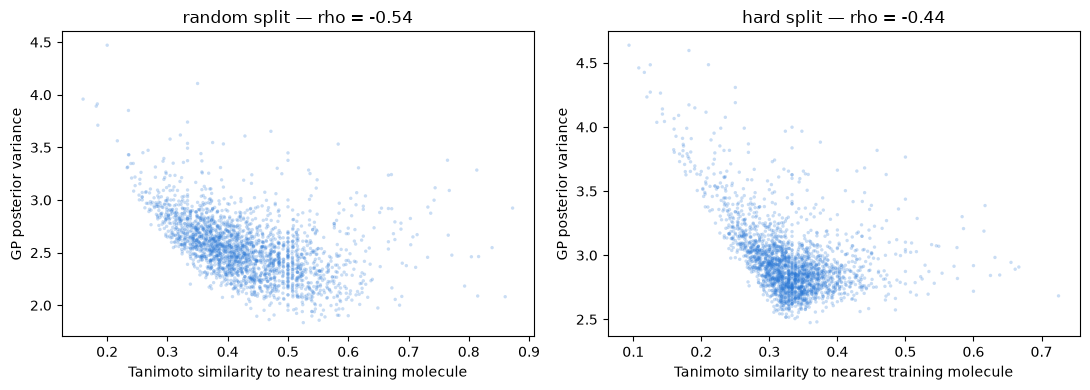

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, split in zip(axes, ["random", "hard"]):
    d = load3(split)
    te = d["test_idx"]
    S = tanimoto(fp[te], fp[(cur[f"split_{split}"] == "train").to_numpy()])
    nn = S.max(1)
    ax.scatter(nn, d["latent_var"], s=6, alpha=0.25, color="#2a78d6", edgecolors="none")
    rho = spearmanr(nn, d["latent_var"]).statistic
    ax.set_xlabel("Tanimoto similarity to nearest training molecule")
    ax.set_ylabel("GP posterior variance")
    ax.set_title(f"{split} split — rho = {rho:+.2f}")
plt.tight_layout(); plt.show()

**It does.** Variance falls steadily as a molecule gets closer to the training set
(rho about -0.5 against the nearest neighbour, about -0.8 against mean similarity to the ten
nearest). The mechanism the proposal describes is real and working.

## 4. Link two: does novelty track error?

This is the link that matters for an applicability domain, and the one that fails.

In [5]:
rows = []
for split in ["random", "cluster", "scaffold", "hard"]:
    d = load3(split)
    te = d["test_idx"]
    S = tanimoto(fp[te], fp[(cur[f"split_{split}"] == "train").to_numpy()])
    nn, dens = S.max(1), np.sort(S, axis=1)[:, -10:].mean(1)
    prob, var = d["prob"], d["latent_var"]
    err = np.abs(prob - y[te])
    rows.append({
        "split": split,
        "var ~ novelty": spearmanr(var, nn).statistic,
        "var ~ density": spearmanr(var, dens).statistic,
        "novelty ~ error": spearmanr(nn, err).statistic,
        "var ~ error": spearmanr(var, err).statistic,
        "|p-0.5| ~ error": spearmanr(np.abs(prob - 0.5), err).statistic,
    })
links = pd.DataFrame(rows).set_index("split")
links.round(3)

,var ~ novelty,var ~ density,novelty ~ error,var ~ error,|p-0.5| ~ error
split,,,,,
random,-0.542,-0.845,-0.057,-0.093,-0.837
cluster,-0.615,-0.860,-0.065,-0.020,-0.810
scaffold,-0.595,-0.877,-0.046,-0.026,-0.822
hard,-0.441,-0.793,-0.028,-0.064,-0.798


Reading the row: variance knows where it is (`var ~ novelty` around -0.5), but being somewhere
unusual does not make the prediction wrong (`novelty ~ error` about -0.03 to -0.06, i.e.
nothing). So variance cannot flag errors either (`var ~ error` about -0.05).

Meanwhile the plain distance from the decision boundary, `|p - 0.5|`, predicts error strongly
(-0.80 to -0.84).

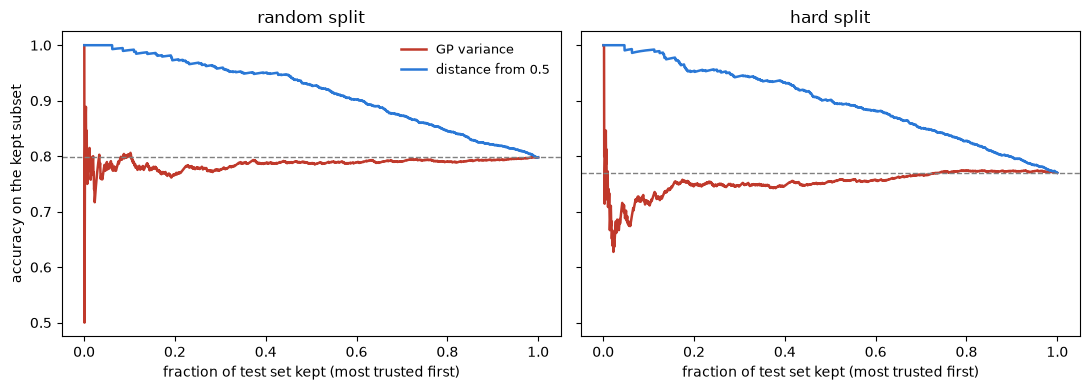

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, split in zip(axes, ["random", "hard"]):
    d = load3(split)
    te = d["test_idx"]
    prob, var = d["prob"], d["latent_var"]
    correct = (prob > 0.5) == y[te]
    for signal, label, color in [(var, "GP variance", "#c0392b"),
                                 (-np.abs(prob - 0.5), "distance from 0.5", "#2a78d6")]:
        order = np.argsort(signal)                    # most trusted first
        acc = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)
        ax.plot(np.arange(1, len(order) + 1) / len(order), acc, lw=1.8, color=color, label=label)
    ax.axhline(correct.mean(), ls="--", color="0.5", lw=1)
    ax.set_xlabel("fraction of test set kept (most trusted first)")
    ax.set_title(f"{split} split")
axes[0].set_ylabel("accuracy on the kept subset")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

A usable confidence signal makes this curve start high on the left and fall towards the dashed
overall accuracy. `|p - 0.5|` does exactly that. GP variance is flat — selecting by it is no
better than keeping a random subset.

In [7]:
# the same thing as numbers: accuracy inside the most and least trusted fifths
rows = []
for split in ["random", "cluster", "scaffold", "hard"]:
    d = load3(split)
    te = d["test_idx"]
    prob, var = d["prob"], d["latent_var"]
    correct = (prob > 0.5) == y[te]
    k = len(te) // 5
    for signal, label in [(var, "GP variance"), (-np.abs(prob - 0.5), "distance from 0.5")]:
        o = np.argsort(signal)
        rows.append({"split": split, "signal": label,
                     "most trusted 20%": correct[o[:k]].mean(),
                     "least trusted 20%": correct[o[-k:]].mean(),
                     "gap": correct[o[:k]].mean() - correct[o[-k:]].mean()})
pd.DataFrame(rows).pivot(index="split", columns="signal",
                         values=["most trusted 20%", "least trusted 20%", "gap"]).round(3)

most trusted 20%                   least trusted 20%  \
signal        GP variance distance from 0.5       GP variance   
split                                                           
cluster             0.804             0.971             0.767   
hard                0.747             0.954             0.756   
random              0.767             0.974             0.830   
scaffold            0.800             0.958             0.811   

                                   gap                    
signal   distance from 0.5 GP variance distance from 0.5  
split                                                     
cluster              0.593       0.037             0.379  
hard                 0.540      -0.009             0.414  
random               0.608      -0.064             0.366  
scaffold             0.597      -0.011             0.361

## 5. Why the chain breaks

Flying is decided by a few local features — a basic nitrogen to accept the proton, an acid to
refuse it. A molecule can be unlike anything in the training set and still carry an obvious
basic amine, and the model calls it correctly. Conversely the molecules the GP is *most*
certain about sit in the crowded middle of the library, which is also where the borderline
cases live.

Global similarity, which is what a Tanimoto kernel measures, is not the right notion of
"familiar" for a property driven by local chemistry.

In [8]:
d = load3("random")
te = d["test_idx"]
chem = pd.read_csv(PROC / "features_chem.csv").iloc[te]
S = tanimoto(fp[te], fp[(cur["split_random"] == "train").to_numpy()])
q = pd.qcut(S.max(1), 4, labels=["most novel", "", " ", "most familiar"])
pd.DataFrame({
    "novelty quartile": q,
    "accuracy": (d["prob"] > 0.5) == y[te],
    "has basic N": chem["has_basic_N"].to_numpy(),
    "mean |p-0.5|": np.abs(d["prob"] - 0.5),
}).groupby("novelty quartile", observed=True).mean().round(3)

,accuracy,has basic N,mean |p-0.5|
novelty quartile,,,
most novel,0.785,0.629,0.221
,0.775,0.600,0.224
,0.821,0.645,0.221
most familiar,0.811,0.668,0.239


## 6. Calibration

Accuracy aside, are the GP's probabilities honest? The Laplace approximation shrinks them
towards 0.5 in proportion to the posterior variance, which should help here.

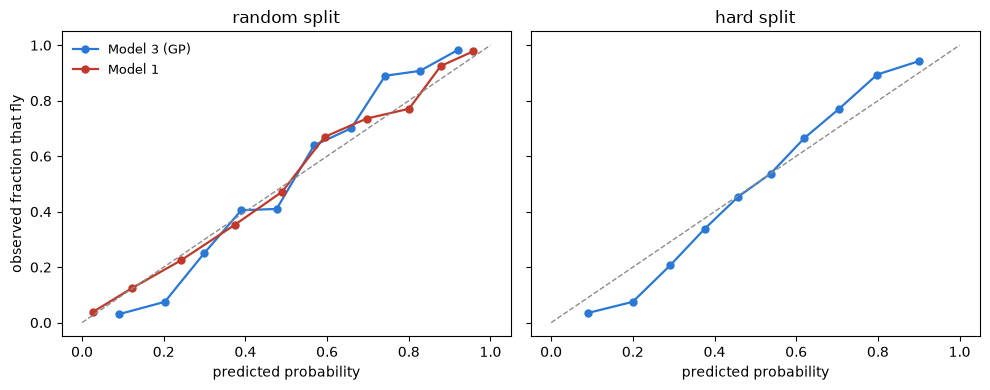

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, split in zip(axes, ["random", "hard"]):
    d = load3(split)
    te = d["test_idx"]
    frac, pred = calibration_curve(y[te], d["prob"], n_bins=10, strategy="quantile")
    ax.plot(pred, frac, "o-", ms=5, lw=1.6, color="#2a78d6", label="Model 3 (GP)")
    if split in set(m1["split"]):
        p1 = np.load(PROC / f"model1_chem_{ADDITIVE}_{split}_ard_laplace.npz")["test_pred"]
        frac1, pred1 = calibration_curve(y[te], p1, n_bins=10, strategy="quantile")
        ax.plot(pred1, frac1, "o-", ms=5, lw=1.6, color="#c0392b", label="Model 1")
    ax.plot([0, 1], [0, 1], "--", color="0.55", lw=1)
    ax.set_title(f"{split} split"); ax.set_xlabel("predicted probability")
axes[0].set_ylabel("observed fraction that fly"); axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 7. What Model 3 settles

- **Best accuracy so far.** AUC 0.879 random, and it holds up best of the three on the hard
  split (0.858), so similarity-based prediction does generalise better than fixed features.
- **The applicability-domain claim needs rewriting.** The GP's variance is a working novelty
  detector, but on this task novelty is not what makes predictions wrong, so variance is not a
  usable reliability signal. The proposal should say so rather than assume the link.
- **There is still a good answer to "when should I trust this?"** — the distance from 0.5.
  Keeping the most confident fifth gives about 97% accuracy against 60% for the least confident
  fifth. That is a usable screen, it just is not the Bayesian part doing the work.

### Still open

- the proposal's plan to use MS2Quant / the EPA model as the GP's prior mean, which would let
  it learn only what is specific to the Echo-MS (needs checking whether those are installable)
- Models 1 and 2 on the scaffold and hard splits, for a complete table
- neural fingerprints, Josh's suggestion, now with a clear motivation: `s_model` from Model 2
  says the bottleneck is the representation, not the instrument